# Tp << Inteligence artificielle pour la cybersecurité >>

## Partie 1 : Découverte a préparation de données 

**Importation des bibliothéques**  
  

Les bibliothéques requises sont dans le fichier **requirements.txt**  
On peut les installer avec la commande : ***pip install -r requirements.txt***

In [4]:
# Dataframes annd array manipulation 

import numpy as np 
import pandas as pd 

# Plotting and figures 

import matplotlib.pyplot as plt 
import seaborn as  sns 

# Machine learning 

from sklearn.preprocessing import StandardScaler , MinMaxScaler , OneHotEncoder
from sklearn.model_selection import train_test_split , GridSearchCV 
from sklearn.metrics import confusion_matrix , accuracy_score , precision_score , recall_score , f1_score
from sklearn.neighbors import KNeighborsClassifier 



In [5]:

df_test = pd.read_csv("NSL-KDD/KDDTest+.txt")
df_train = pd.read_csv("NSL-KDD/KDDTrain+.txt")


print(df_train.head())
print(df_test.head())

   duration protocol_type  ... sub_attack  difficulty_level
0         0           tcp  ...     normal                20
1         0           udp  ...     normal                15
2         0           tcp  ...    neptune                19
3         0           tcp  ...     normal                21
4         0           tcp  ...     normal                21

[5 rows x 43 columns]
   duration protocol_type  ... sub_attack  difficulty_level
0         0           tcp  ...    neptune                21
1         0           tcp  ...    neptune                21
2         2           tcp  ...     normal                21
3         0          icmp  ...      saint                15
4         1           tcp  ...      mscan                11

[5 rows x 43 columns]


In [6]:
print(df_test.info)
print(df_train.info)

<bound method DataFrame.info of        duration protocol_type  ... sub_attack  difficulty_level
0             0           tcp  ...    neptune                21
1             0           tcp  ...    neptune                21
2             2           tcp  ...     normal                21
3             0          icmp  ...      saint                15
4             1           tcp  ...      mscan                11
...         ...           ...  ...        ...               ...
22539         0           tcp  ...     normal                21
22540         0           tcp  ...     normal                21
22541         0           tcp  ...       back                15
22542         0           udp  ...     normal                21
22543         0           tcp  ...      mscan                14

[22544 rows x 43 columns]>
<bound method DataFrame.info of         duration protocol_type  ... sub_attack  difficulty_level
0              0           tcp  ...     normal                20
1         

**Nombre d'observations :**  
- Dans le jeu de données d'entrainement : 125973 observation 
- Dans le jeu de données de test :  22544 observation 

In [7]:
print("Nombre de variables : " , df_test.columns.shape[0]
)

Nombre de variables :  43


In [8]:
# Classe a predire 

print("Classe a predire : " , df_train.columns[-2])

Classe a predire :  sub_attack


In [9]:
# Variables numeriques / catégorielles 

#Variables numériques

print("Les variables numeriques : \n ")
for var in df_train.dtypes[(df_train.dtypes == "int64") | (df_train.dtypes == "float64")].index : 
    print(var)

Les variables numeriques : 
 
duration
src_bytes
dst_bytes
land
wrong_fragment
urgent
hot
num_failed_logins
logged_in
num_compromised
root_shell
su_attempted
num_root
num_file_creations
num_shells
num_access_files
num_outbound_cmds
is_host_login
is_guest_login
count
srv_count
serror_rate
srv_serror_rate
rerror_rate
srv_rerror_rate
same_srv_rate
diff_srv_rate
srv_diff_host_rate
dst_host_count
dst_host_srv_count
dst_host_same_srv_rate
dst_host_diff_srv_rate
dst_host_same_src_port_rate
dst_host_srv_diff_host_rate
dst_host_serror_rate
dst_host_srv_serror_rate
dst_host_rerror_rate
dst_host_srv_rerror_rate
difficulty_level


In [10]:
print("Les variables categorielles : \n ")
for var in df_train.dtypes[(df_train.dtypes != "int64") & (df_train.dtypes != "float64")].index : 
    print(var)


Les variables categorielles : 
 
protocol_type
service
flag
sub_attack


In [11]:
# Les differentes valeurs prises par les variables categorielles : 

print("Les differentes valeurs prises par variables categorielles : \n ")
for var in df_train.dtypes[(df_train.dtypes != "int64") & (df_train.dtypes != "float64")].index : 
    print("La variable " , var , ": \n")
    print(df_train[var].unique().var)
    print("\n\n")

Les differentes valeurs prises par variables categorielles : 
 
La variable  protocol_type : 

<bound method StringArray.var of <StringArray>
['tcp', 'udp', 'icmp']
Length: 3, dtype: str>



La variable  service : 



<bound method StringArray.var of <StringArray>
[   'ftp_data',       'other',     'private',        'http',  'remote_job',
        'name',  'netbios_ns',       'eco_i',         'mtp',      'telnet',
      'finger',    'domain_u',      'supdup',   'uucp_path',      'Z39_50',
        'smtp',    'csnet_ns',        'uucp', 'netbios_dgm',       'urp_i',
        'auth',      'domain',         'ftp',         'bgp',        'ldap',
       'ecr_i',      'gopher',       'vmnet',      'systat',    'http_443',
         'efs',       'whois',       'imap4',    'iso_tsap',        'echo',
      'klogin',        'link',      'sunrpc',       'login',      'kshell',
     'sql_net',        'time',   'hostnames',        'exec',       'ntp_u',
     'discard',        'nntp',     'courier',         'ctf',         'ssh',
     'daytime',       'shell',     'netstat',       'pop_3',        'nnsp',
         'IRC',       'pop_2',     'printer',       'tim_i',     'pm_dump',
       'red_i', 'netbios_ssn',         'r

In [12]:

# Verification des valeurs nulls : 
Nulls_train = df_train.isnull().sum()
Nulls_test = df_test.isnull().sum()
print(Nulls_train[Nulls_train != 0])
print(Nulls_test[Nulls_test != 0])

Series([], dtype: int64)
Series([], dtype: int64)


Pas de valeurs nulls 

In [13]:
# Statistiques discriptives 

# jeu de données de test 

df_test.describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,difficulty_level
count,22544.000000,2.254400e+04,2.254400e+04,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.0,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000,22544.000000
mean,218.859076,1.039545e+04,2.056019e+03,0.000311,0.008428,0.000710,0.105394,0.021647,0.442202,0.119899,0.002440,0.000266,0.114665,0.008738,0.001153,0.003549,0.0,0.000488,0.028433,79.028345,31.124379,0.102924,0.103635,0.238463,0.235179,0.740345,0.094074,0.098110,193.869411,140.750532,0.608722,0.090540,0.132261,0.019638,0.097814,0.099426,0.233385,0.226683,18.017965
std,1407.176612,4.727864e+05,2.121930e+04,0.017619,0.142599,0.036473,0.928428,0.150328,0.496659,7.269597,0.049334,0.021060,8.041614,0.676842,0.048014,0.067829,0.0,0.022084,0.166211,128.539248,89.062532,0.295367,0.298332,0.416118,0.416215,0.412496,0.259138,0.253545,94.035663,111.783972,0.435688,0.220717,0.306268,0.085394,0.273139,0.281866,0.387229,0.400875,4.270361
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.250000,0.000000,0.000000,121.000000,15.000000,0.070000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000
50%,0.000000,5.400000e+01,4.600000e+01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,8.000000,6.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,255.000000,168.000000,0.920000,0.010000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
75%,0.000000,2.870000e+02,6.010000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,123.250000,16.000000,0.000000,0.000000,0.250000,0.072500,1.000000,0.060000,0.000000,255.000000,255.000000,1.000000,0.060000,0.030000,0.010000,0.000000,0.000000,0.360000,0.170000,21.000000
max,57715.000000,6.282565e+07,1.345927e+06,1.000000,3.000000,3.000000,101.000000,4.000000,1.000000,796.000000,1.000000,2.000000,878.000000,100.000000,5.000000,4.000000,0.0,1.000000,1.000000,511.000000,511.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,255.000000,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,21.000000


In [14]:
# jeu de donnée d'entrainement 

df_train.describe()

,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,difficulty_level
count,125973.00000,1.259730e+05,1.259730e+05,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.0,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000
mean,287.14465,4.556674e+04,1.977911e+04,0.000198,0.022687,0.000111,0.204409,0.001222,0.395736,0.279250,0.001342,0.001103,0.302192,0.012669,0.000413,0.004096,0.0,0.000008,0.009423,84.107555,27.737888,0.284485,0.282485,0.119958,0.121183,0.660928,0.063053,0.097322,182.148945,115.653005,0.521242,0.082951,0.148379,0.032542,0.284452,0.278485,0.118832,0.120240,19.504060
std,2604.51531,5.870331e+06,4.021269e+06,0.014086,0.253530,0.014366,2.149968,0.045239,0.489010,23.942042,0.036603,0.045154,24.399618,0.483935,0.022181,0.099370,0.0,0.002817,0.096612,114.508607,72.635840,0.446456,0.447022,0.320436,0.323647,0.439623,0.180314,0.259830,99.206213,110.702741,0.448949,0.188922,0.308997,0.112564,0.444784,0.445669,0.306557,0.319459,2.291503
min,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.090000,0.000000,0.000000,82.000000,10.000000,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000
50%,0.00000,4.400000e+01,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,14.000000,8.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,255.000000,63.000000,0.510000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,20.000000
75%,0.00000,2.760000e+02,5.160000e+02,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,143.000000,18.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.060000,0.000000,255.000000,255.000000,1.000000,0.070000,0.060000,0.020000,1.000000,1.000000,0.000000,0.000000,21.000000
max,42908.00000,1.379964e+09,1.309937e+09,1.000000,3.000000,3.000000,77.000000,5.000000,1.000000,7479.000000,1.000000,2.000000,7468.000000,43.000000,2.000000,9.000000,0.0,1.000000,1.000000,511.000000,511.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,255.000000,255.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,21.000000


In [15]:
# Distribution de labels originaux
print("distribution des labels originaux \n")
print("Dans le jeu d'entrainement \n ")
print(df_train["sub_attack"].value_counts())
print("\n")
print("Dans le jeu de test \n ")
print(df_test["sub_attack"].value_counts())
print("\n")

distribution des labels originaux 

Dans le jeu d'entrainement 
 
sub_attack
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2
Name: count, dtype: int64


Dans le jeu de test 
 
sub_attack
normal             9711
neptune            4657
guess_passwd       1231
mscan               996
warezmaster         944
apache2             737
satan               735
processtable        685
smurf               665
back                359
snmpguess           331
saint               31

In [16]:
print("les differents types d'attaques presents : \n ")
for attack in df_train["sub_attack"].unique():
    print(attack)


les differents types d'attaques presents : 
 
normal
neptune
warezclient
ipsweep
portsweep
teardrop
nmap
satan
smurf
pod
back
guess_passwd
ftp_write
multihop
rootkit
buffer_overflow
imap
warezmaster
phf
land
loadmodule
spy
perl


In [17]:
# categorization des attaques 
mapping_attaques = {
    'normal': 'Normal',
    
    # DoS (Denial of Service)
    'neptune': 'DoS', 'back': 'DoS', 'land': 'DoS', 'pod': 'DoS', 
    'smurf': 'DoS', 'teardrop': 'DoS', 'mailbomb': 'DoS', 'apache2': 'DoS', 
    'processtable': 'DoS', 'udpstorm': 'DoS', 'worm': 'DoS',
    
    # Probe (Scanning / Reconnaissance)
    'satan': 'Probe', 'ipsweep': 'Probe', 'nmap': 'Probe', 
    'portsweep': 'Probe', 'mscan': 'Probe', 'saint': 'Probe',
    
    # R2L (Remote to Local)
    'guess_passwd': 'R2L', 'ftp_write': 'R2L', 'imap': 'R2L', 'phf': 'R2L', 
    'multihop': 'R2L', 'warezmaster': 'R2L', 'warezclient': 'R2L', 'spy': 'R2L',
    'xlock': 'R2L', 'xsnoop': 'R2L', 'snmpguess': 'R2L', 'snmpgetattack': 'R2L',
    'httptunnel': 'R2L', 'sendmail': 'R2L', 'named': 'R2L',
    
    # U2R (User to Root)
    'buffer_overflow': 'U2R', 'loadmodule': 'U2R', 'rootkit': 'U2R', 
    'perl': 'U2R', 'sqlattack': 'U2R', 'xterm': 'U2R', 'ps': 'U2R'
}

In [18]:
def categoriser_attaque(label):
    return mapping_attaques.get(label, 'Inconnu')

df_train['attack_category'] = df_train["sub_attack"].apply(categoriser_attaque)
df_test['attack_category'] = df_test["sub_attack"].apply(categoriser_attaque)

In [19]:
# Distribution des cinq categories

# dans le jeu d'entrainement

print("distribution des cinq categoris dans le jeu d'entrainement \n")
print(df_train["attack_category"].value_counts())
print("\n")

# dans le jeu de test 
print("distribution des cinq categoris dans le jeu d'entrainement \n")
print(df_test["attack_category"].value_counts())
print("\n")

distribution des cinq categoris dans le jeu d'entrainement 

attack_category
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64


distribution des cinq categoris dans le jeu d'entrainement 

attack_category
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64




In [20]:

# construction de la cible y 

def construction_cible(df):
     df["y"] = df["attack_category"].map({'Normal' :0 , 'DoS' : 1 , 'Probe' : 2 , 'R2L' : 3 , 'U2R' : 4})
     return df

df_train = construction_cible(df_train)
df_test = construction_cible(df_test)

print(df_test["y"].value_counts() , df_train["y"].value_counts())

y
0    9711
1    7460
3    2885
2    2421
4      67
Name: count, dtype: int64 y
0    67343
1    45927
2    11656
3      995
4       52
Name: count, dtype: int64


In [21]:
print(df_train.columns)
print(df_test.columns)

Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot',
       'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell',
       'su_attempted', 'num_root', 'num_file_creations', 'num_shells',
       'num_access_files', 'num_outbound_cmds', 'is_host_login',
       'is_guest_login', 'count', 'srv_count', 'serror_rate',
       'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate',
       'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count',
       'dst_host_srv_count', 'dst_host_same_srv_rate',
       'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
       'dst_host_srv_diff_host_rate', 'dst_host_serror_rate',
       'dst_host_srv_serror_rate', 'dst_host_rerror_rate',
       'dst_host_srv_rerror_rate', 'sub_attack', 'difficulty_level',
       'attack_category', 'y'],
      dtype='str')
Index(['duration', 'protocol_type', 'service', 'flag', 'src_bytes',
       'dst_bytes', 'land', 

In [22]:
# Suppression des valeurs cibles precedentes 

df_train = df_train.drop(columns = ['sub_attack' , 'attack_category'])
df_test = df_test.drop(columns=['sub_attack' , 'attack_category'])

In [23]:
# Separation cible / vars explicatives 

x_train = df_train.drop(columns = ["y"]) # tests 
y_train = df_train["y"] # answers

x_test =  df_test.drop(columns = ["y"]) 
y_test =  df_test["y"] 

print(x_train.head())
print(x_test.head())
print(y_train.head())
print(y_test.head())

   duration protocol_type  ...  dst_host_srv_rerror_rate  difficulty_level
0         0           tcp  ...                      0.00                20
1         0           udp  ...                      0.00                15
2         0           tcp  ...                      0.00                19
3         0           tcp  ...                      0.01                21
4         0           tcp  ...                      0.00                21

[5 rows x 42 columns]
   duration protocol_type  ...  dst_host_srv_rerror_rate  difficulty_level
0         0           tcp  ...                      1.00                21
1         0           tcp  ...                      1.00                21
2         2           tcp  ...                      0.00                21
3         0          icmp  ...                      0.00                15
4         1           tcp  ...                      0.71                11

[5 rows x 42 columns]
0    0
1    0
2    1
3    0
4    0
Name: y, dtype: int

In [24]:
# Separation des variables categoriques et variables numeriques 

cat = ["protocol_type" , "service" , "flag"] # variables categoriques 

# variables numeriques 

x_train_num = x_train.drop(columns = cat) 
x_test_num = x_test.drop(columns = cat) 


print(x_train_num.dtypes)

print(x_test_num.dtypes)

duration                         int64
src_bytes                        int64
dst_bytes                        int64
land                             int64
wrong_fragment                   int64
urgent                           int64
hot                              int64
num_failed_logins                int64
logged_in                        int64
num_compromised                  int64
root_shell                       int64
su_attempted                     int64
num_root                         int64
num_file_creations               int64
num_shells                       int64
num_access_files                 int64
num_outbound_cmds                int64
is_host_login                    int64
is_guest_login                   int64
count                            int64
srv_count                        int64
serror_rate                    float64
srv_serror_rate                float64
rerror_rate                    float64
srv_rerror_rate                float64
same_srv_rate            

In [25]:
# variables categoriques 
x_train_cat = x_train[cat]
x_test_cat = x_test[cat]

print(x_train_cat.dtypes)
print(x_test_cat.dtypes)

protocol_type    str
service          str
flag             str
dtype: object
protocol_type    str
service          str
flag             str
dtype: object


In [26]:
# Encodage des variables categoriques : One Hot Encoding 

# instance de Onhotencoder
ohe = OneHotEncoder(sparse_output=False, handle_unknown='ignore')



encoded_train = ohe.fit_transform(x_train_cat)

# 2. Transform ONLY the test data (do NOT call fit_transform here)
encoded_test = ohe.transform(x_test_cat)

# 3. Extract column names from the fitted encoder
feature_names = ohe.get_feature_names_out(cat)

# 4. Create DataFrames
x_train_cat_encoded = pd.DataFrame(encoded_train, columns=feature_names, dtype=int)
x_test_cat_encoded = pd.DataFrame(encoded_test, columns=feature_names, dtype=int)

print(x_train_cat_encoded.head())
print(x_test_cat_encoded.head())
print(x_train_cat_encoded.columns)
print(x_test_cat_encoded.columns)




   protocol_type_icmp  protocol_type_tcp  ...  flag_SF  flag_SH
0                   0                  1  ...        1        0
1                   0                  0  ...        1        0
2                   0                  1  ...        0        0
3                   0                  1  ...        1        0
4                   0                  1  ...        1        0

[5 rows x 84 columns]
   protocol_type_icmp  protocol_type_tcp  ...  flag_SF  flag_SH
0                   0                  1  ...        0        0
1                   0                  1  ...        0        0
2                   0                  1  ...        1        0
3                   1                  0  ...        1        0
4                   0                  1  ...        0        0

[5 rows x 84 columns]
Index(['protocol_type_icmp', 'protocol_type_tcp', 'protocol_type_udp',
       'service_IRC', 'service_X11', 'service_Z39_50', 'service_aol',
       'service_auth', 'service_bgp', 'servic

In [27]:
# La nouvelle dimension de x

print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(125973, 42)
(22544, 42)
(125973,)
(22544,)


In [28]:
# jeu de données completemnt numerique

x_train = pd.concat([x_train_num , x_train_cat_encoded], axis =1)
x_test = pd.concat([x_test_num, x_test_cat_encoded], axis =1)

print(x_train.dtypes[(x_train.dtypes != "int64")&(x_train.dtypes !="float64")])
print(x_test.dtypes[(x_test.dtypes != "int64")&(x_test.dtypes !="float64")])

print("Tous les donneés sont numériques")

Series([], dtype: object)
Series([], dtype: object)
Tous les donneés sont numériques


In [29]:
# SEPARATION APPRENTISSAGE / TEST 

x_train , x_val , y_train , y_val = train_test_split(x_train,y_train, test_size = 0.2, random_state = 42 )

print(x_train.shape)
print(x_val.shape)

print(y_train.shape)
print(y_val.shape)



(100778, 123)
(25195, 123)
(100778,)
(25195,)


In [30]:
# Scaling data 

# On utitlise le StandardScaler

scaler = StandardScaler()
x_train  = scaler.fit_transform(x_train)
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [31]:
# Verification finale 

In [32]:
# Dimensions 
print("La dimension de x_train : ",x_train.shape )
print("La dimension de x_val : ", x_val.shape )
print("La dimension de x_test : ",x_test.shape )
print("La dimension de y_train : ", y_train.shape )
print("La dimension de y_val : ", y_val.shape )
print("La dimension de y_test : ",y_test.shape )

print("\n\n")

print("le type de x_train " , x_train.dtype)
print("le type de x_val " , x_val.dtype)
print("le type de x_test " , x_test.dtype)

print("le type de y_train " , x_train.dtype)
print("le type de y_val " , x_val.dtype)
print("le type de y_test " , x_test.dtype)

print("\n\n")

print("les classes dans y_train : " , y_train.unique())
print("les classes dans y_val : " , y_val.unique())
print("les classes dans y_test : " , y_test.unique())

# Standardisation 

print("\n\n Verification de la standardisation , (moyenne proche de 0 , ecart type proche de 1)\n\n")

print("moyenne x_train" , np.mean(x_train))
print("moyenne x_val" , np.mean(x_val))
print("moyenne x_test" , np.mean(x_test))

print("\n")

print("ecart type x_train" , np.std(x_train))
print("ecart type x_val" , np.std(x_val))
print("ecart type x_test" , np.std(x_test))

print("\n Les valeurs sont standardisés")




La dimension de x_train :  (100778, 123)
La dimension de x_val :  (25195, 123)
La dimension de x_test :  (22544, 123)
La dimension de y_train :  (100778,)
La dimension de y_val :  (25195,)
La dimension de y_test :  (22544,)



le type de x_train  float64
le type de x_val  float64
le type de x_test  float64
le type de y_train  float64
le type de y_val  float64
le type de y_test  float64



les classes dans y_train :  [0 1 2 3 4]
les classes dans y_val :  [0 1 2 3 4]
les classes dans y_test :  [1 0 2 3 4]


 Verification de la standardisation , (moyenne proche de 0 , ecart type proche de 1)


moyenne x_train -3.842849380224868e-18
moyenne x_val -0.00011070736169709524
moyenne x_test 0.011553451693542369




ecart type x_train 0.9959266633137136
ecart type x_val 1.0070135981251496
ecart type x_test 1.388798880152258

 Les valeurs sont standardisés


## Partie 2 :  Machine learning classique

**Objectif**  
  

Application de plusieurs méthodes classiques de classification au meme probleme et comparer leur comportement sur le meme ju  de données  

 **Les Méthodes étudiées sont :**  
 1. K-nearest neighbors
 2. Naive Bayes
 3. Régression logistique
 4. SVM
 5. Arbre de décision


*1. Knearest neighbors (KNN)*

In [33]:
# Construire un classificateurs
def construct_kn(neighbors):
    knn = KNeighborsClassifier(n_neighbors=neighbors)
    knn.fit(x_train,y_train)
    return knn

knns = {}
def prediction(knn , x_predict):
    y_pred = knn.predict(x_predict)
    return {"neighbors":knn.n_neighbors,"prediction":y_pred}
neighbors = [3,5,7,11,15]

for n in neighbors:
    knns[n]=prediction(construct_kn(n),x_val)
print(knns)


{3: {'neighbors': 3, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 5: {'neighbors': 5, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 7: {'neighbors': 7, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 11: {'neighbors': 11, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 15: {'neighbors': 15, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}}


In [34]:
# Procedure d'evaluation
def eval_knns(knns ,real_y):
    results = {}
    
    for key, item in knns.items():
        # Retrieve y_pred and neighbor count based on dictionary structure
        if isinstance(item, dict):
            y_pred = item["prediction"]
            neighbors = item["neighbors"]
        # Compute evaluation metrics comparing y_pred with y_val
        results[key] = {
            "neighbors": neighbors,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='weighted'),
            "recall": recall_score(real_y, y_pred, average='weighted'),
            "f1score": f1_score(real_y, y_pred, average='weighted'),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        
    return results    
def eval_kn(kn ,real_y):
    
    
    y_pred = kn["prediction"]
    neighbors = kn["neighbors"]
    # Compute evaluation metrics comparing y_pred with y_val
    results = {
            "neighbors": neighbors,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='weighted'),
            "recall": recall_score(real_y, y_pred, average='weighted'),
            "f1score": f1_score(real_y, y_pred, average='weighted'),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        
    return results  

In [35]:
# Evaluation des valeurs

resultats = eval_knns(knns,y_val)

# Comparaison des valeurs
df_results = pd.DataFrame(resultats).T
print(df_results)

   neighbors  ...                                   confusion_matrix
3          3  ...  [[13403, 2, 9, 6, 2], [6, 9174, 1, 0, 0], [6, ...
5          5  ...  [[13400, 7, 9, 5, 1], [6, 9174, 1, 0, 0], [12,...
7          7  ...  [[13397, 10, 11, 3, 1], [6, 9174, 1, 0, 0], [2...
11        11  ...  [[13390, 13, 11, 5, 3], [7, 9171, 3, 0, 0], [2...
15        15  ...  [[13388, 16, 13, 5, 0], [4, 9171, 6, 0, 0], [2...

[5 rows x 6 columns]


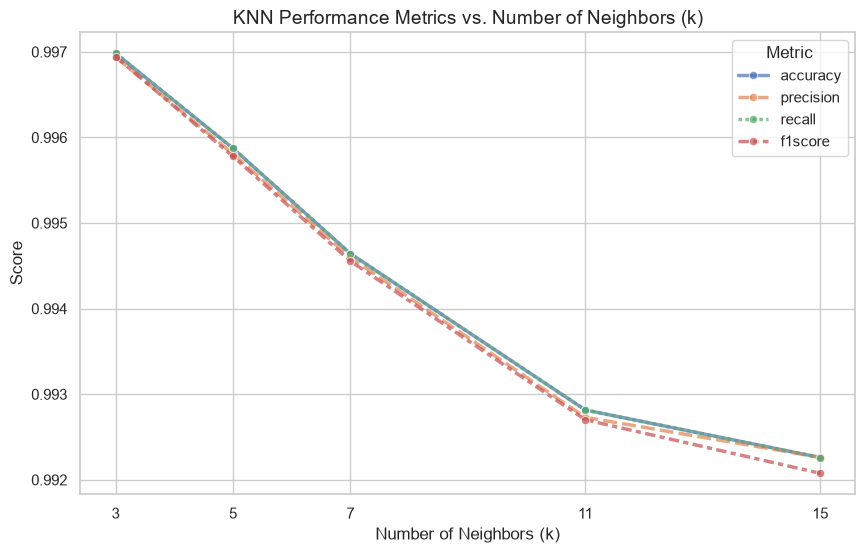

In [104]:


# 1. Convert to DataFrame and transpose
df = pd.DataFrame(resultats).T

# 2. Cast columns to proper numeric types (fixes the object dtype issue)
metrics = ['accuracy', 'precision', 'recall', 'f1score']
for col in metrics:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['neighbors'] = pd.to_numeric(df['neighbors'], errors='coerce', downcast='integer')

# 3. Reshape into long format
df_long = df.melt(id_vars=['neighbors'], value_vars=metrics, var_name='Metric', value_name='Score')

# 4. Plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=df_long, 
    x='neighbors', 
    y='Score', 
    hue='Metric',
    style='Metric', 
    marker='o', 
    linewidth=2.5,
    alpha=0.7
)

plt.title('KNN Performance Metrics vs. Number of Neighbors (k)', fontsize=14)
plt.xlabel('Number of Neighbors (k)', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.xticks(df['neighbors'].unique())
plt.legend(title='Metric')

plt.show()

Matrice de confusion KNN avec  3 voisins 




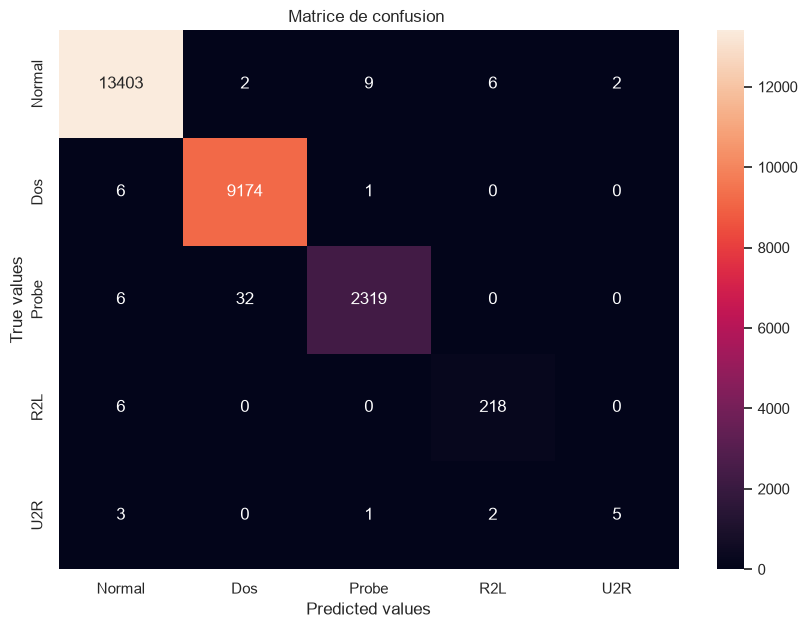

Matrice de confusion KNN avec  5 voisins 




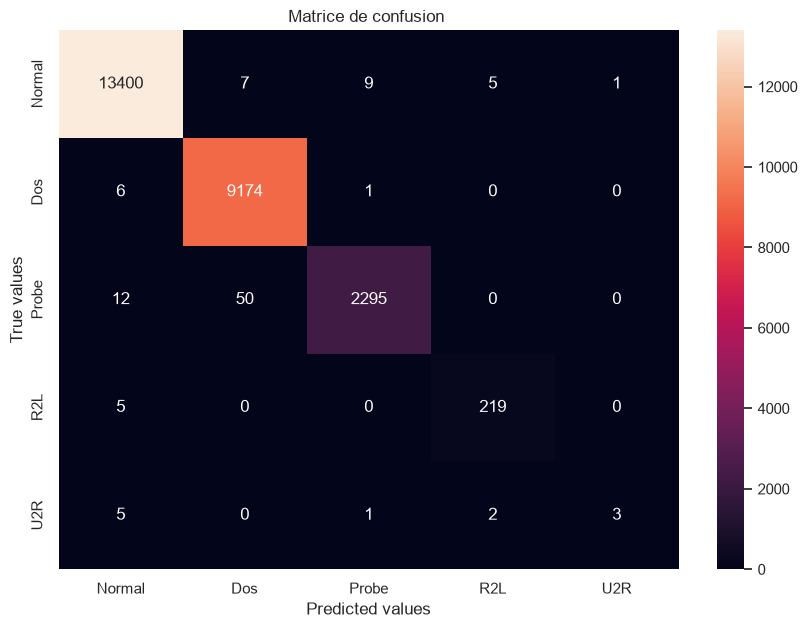

Matrice de confusion KNN avec  7 voisins 




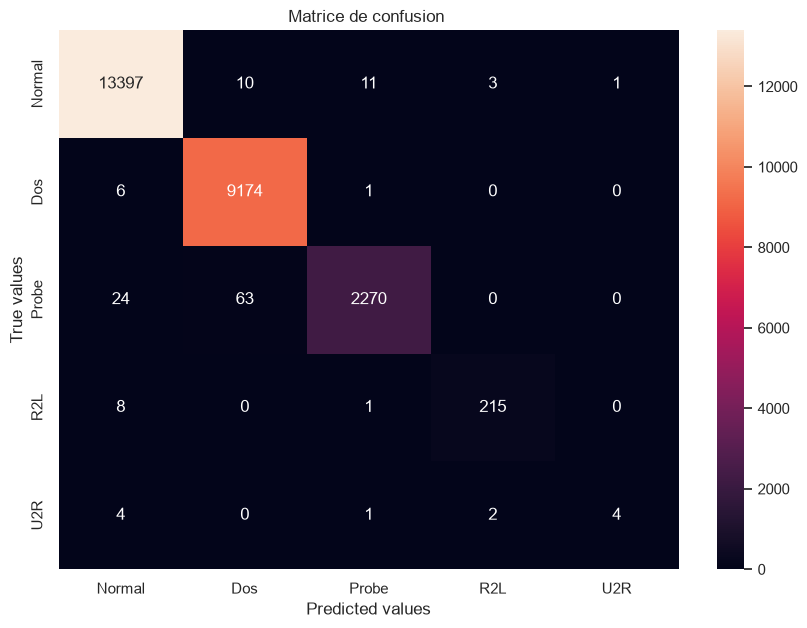

Matrice de confusion KNN avec  11 voisins 




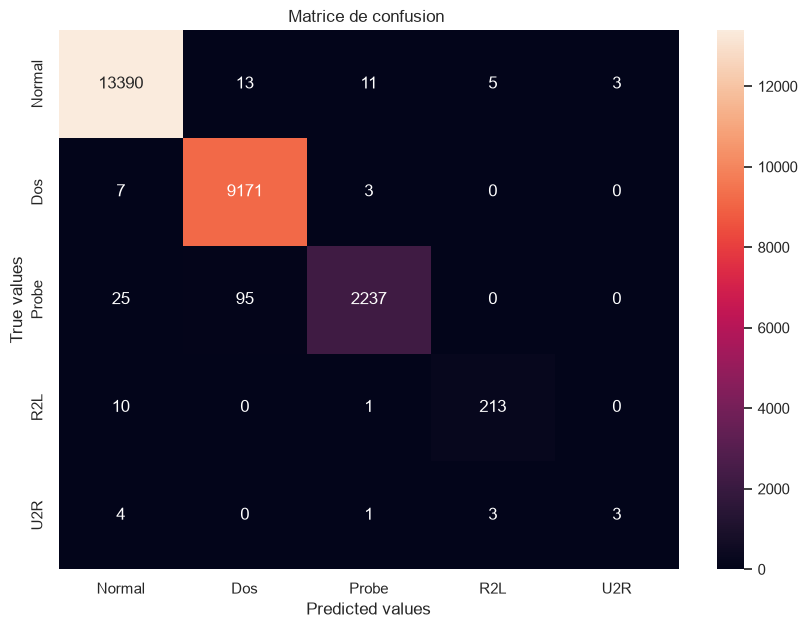

Matrice de confusion KNN avec  15 voisins 




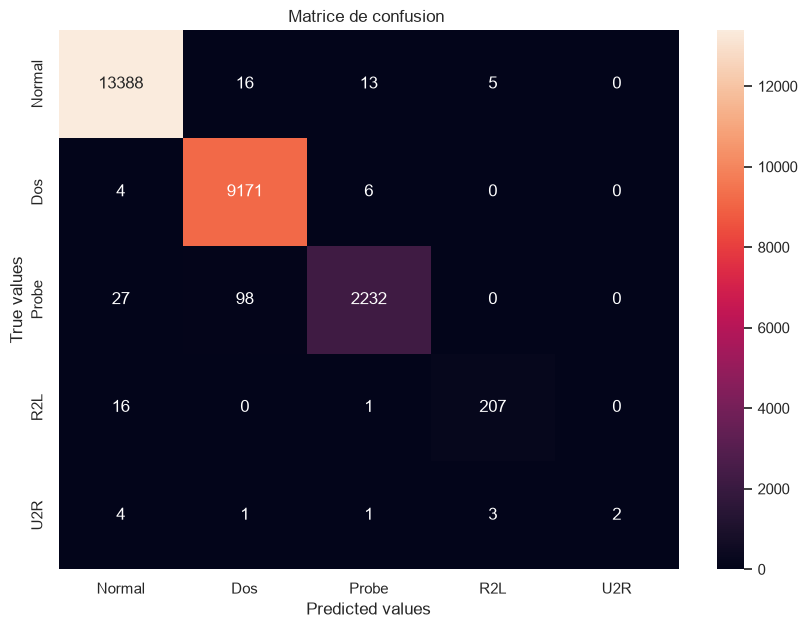

In [37]:
#Matrices de confusion 

def mat_conf(matrix):
    plt.figure(figsize = (10,7))
    sns.heatmap(matrix , annot = True , fmt = "d" , xticklabels=["Normal" , "Dos" , "Probe" , "R2L" , "U2R"] , yticklabels=["Normal" , "Dos" , "Probe" , "R2L" , "U2R"] )
    plt.title("Matrice de confusion ")
    plt.xlabel("Predicted values")
    plt.ylabel("True values")
    plt.show()

for val in range(0,df.shape[0]):
    print("Matrice de confusion KNN avec ",df.iloc[val]["neighbors"],"voisins \n\n")
    mat_conf(df.iloc[val]["confusion_matrix"])



*choix optimal de voisins :* **3**

Les performances du model deminuent en incrementant le nombre de voisins  

In [38]:
# Choix de configuration 

knn_model_final = construct_kn(3)


neighbors  :  3



accuracy  :  0.7519960965223563



precision  :  0.7885359786180287



recall  :  0.7519960965223563



f1score  :  0.7191846387834738





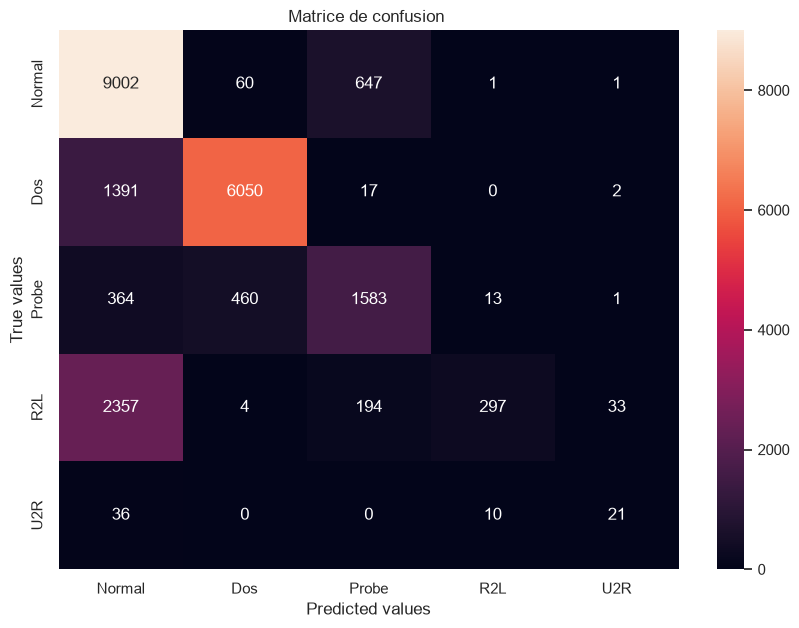

In [39]:
# évaluation du modele sur le jeu de test

y_prediction_test = prediction(knn_model_final,x_test)

knn_evaluation = eval_kn(y_prediction_test,y_test)

for key,value in knn_evaluation.items() :
    if key == "confusion_matrix":
        mat_conf(knn_evaluation["confusion_matrix"])
        break
    print(key ," : " ,  value)
    print("\n\n")




#### **2.Naive Bayes**

In [40]:
#INPORTATION

from sklearn.naive_bayes import GaussianNB

In [41]:
# INITIALISATION / ENTRAINEMENT

def construct_nb():
    gnb = GaussianNB(var_smoothing=1e-8)
    gnb.fit(x_train , y_train)
    return gnb

In [ ]:
# PREDICTION 

gnb = construct_nb()
nb_y_pred = gnb.predict(x_test)



In [43]:
# EVALUATION 

def eval_nb(y_pred ,real_y):
    
    # Compute evaluation metrics comparing y_pred with real_y
    results = {
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='weighted'),
            "recall": recall_score(real_y, y_pred, average='weighted'),
            "f1score": f1_score(real_y, y_pred, average='weighted'),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        
    return results 

nb_evaluation = eval_nb(nb_y_pred,y_test)

accuracy  :  0.4438431511710433



precision  :  0.6226959915027669



recall  :  0.4438431511710433



f1score  :  0.4643326707772961





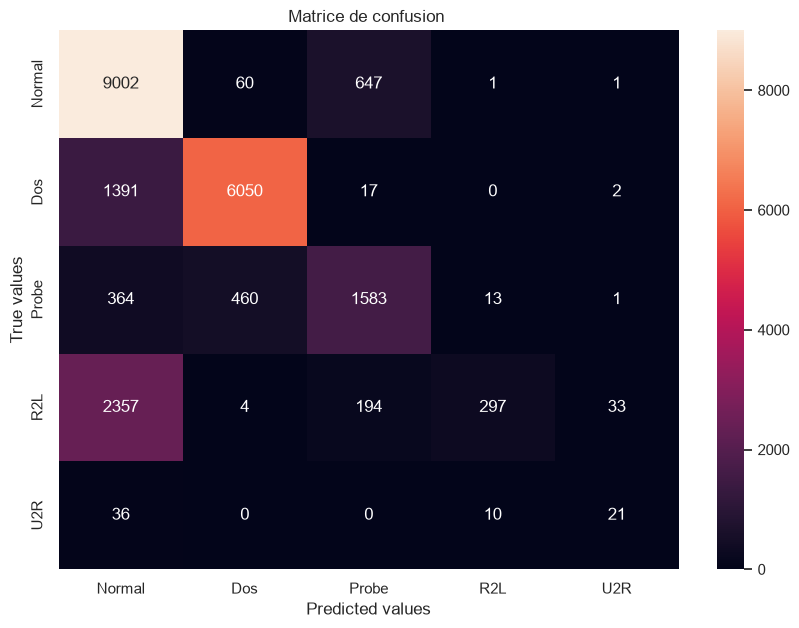

In [44]:
# METRIQUES

for key,value in nb_evaluation.items() :
    if key == "confusion_matrix":
        mat_conf(knn_evaluation["confusion_matrix"])
        break
    print(key ," : " ,  value)
    print("\n\n")

#### **3.Regression logistique**

In [45]:
#IPORTATION
from sklearn.linear_model import LogisticRegression

In [55]:
#INITIALISATION / ENTRAINEMENT

c_vals = {0.1 , 1 , 10}

def construct_lrg(c_val):
    lrg = LogisticRegression(solver='lbfgs' , C=c_val , random_state=42)
    lrg.fit(x_train , y_train)
    return lrg 


In [65]:


train_lrgs = {}
def lrg_prediction(lrg , x_predict):
    y_pred = lrg.predict(x_predict)
    return {"c_val":lrg.C,"prediction":y_pred}

for c_val in c_vals:
    train_lrgs[c_val]=lrg_prediction(construct_lrg(c_val),x_val)
print(lrgs)

{0.1: {'c_val': 0.1, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 1: {'c_val': 1, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}, 10: {'c_val': 10, 'prediction': array([0, 1, 1, ..., 0, 0, 1], shape=(25195,))}}


C:\Users\06697\AppData\Roaming\Python\Python315\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [68]:
#COMPARAISON

def eval_lrgs(lrgs , real_y):
    results = {}

    for key , item in lrgs.items():
        if isinstance(item,dict):
            y_pred = item["prediction"]
            c_val = item["c_val"]
            def eval_lrg(y_pred ,real_y):
                
                # Compute evaluation metrics comparing y_pred with real_y
                results = {
                        "c_val" : c_val,
                        "accuracy": accuracy_score(real_y, y_pred),
                        "precision": precision_score(real_y, y_pred, average='weighted'),
                        "recall": recall_score(real_y, y_pred, average='weighted'),
                        "f1score": f1_score(real_y, y_pred, average='weighted'),
                        "confusion_matrix": confusion_matrix(real_y, y_pred)
                    }
                return results 
        results[key] = eval_lrg(y_pred , real_y)
    return results 


lrg_resultats = eval_lrgs(train_lrgs , y_val)

print(lrg_resultats)
    
        
    


{0.1: {'c_val': 0.1, 'accuracy': 0.9910299662631474, 'precision': 0.9910873088144708, 'recall': 0.9910299662631474, 'f1score': 0.9909830147486949, 'confusion_matrix': array([[13307,    41,    56,    18,     0],
       [   28,  9152,     1,     0,     0],
       [   57,     8,  2291,     1,     0],
       [    8,     0,     1,   215,     0],
       [    0,     0,     1,     6,     4]])}, 1: {'c_val': 1, 'accuracy': 0.9919428458027386, 'precision': 0.9920036914754634, 'recall': 0.9919428458027386, 'f1score': 0.9919140556175969, 'confusion_matrix': array([[13314,    38,    52,    18,     0],
       [   19,  9162,     0,     0,     0],
       [   52,    11,  2293,     1,     0],
       [    5,     0,     1,   218,     0],
       [    0,     0,     1,     5,     5]])}, 10: {'c_val': 10, 'accuracy': 0.992101607461798, 'precision': 0.9921228023723045, 'recall': 0.992101607461798, 'f1score': 0.9920747682323376, 'confusion_matrix': array([[13319,    37,    50,    16,     0],
       [   21,  916

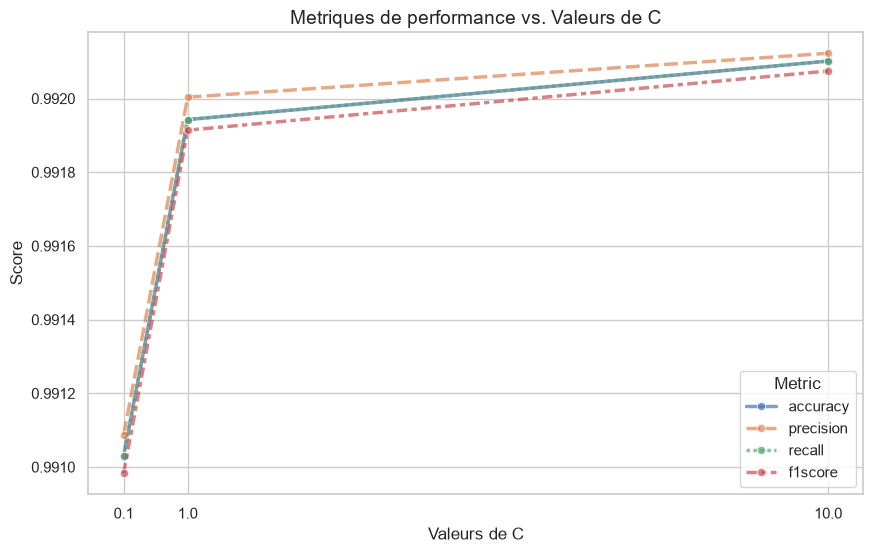

In [99]:
# 1. Convert to DataFrame and transpose
df = pd.DataFrame(lrg_resultats).T

# 2. Cast columns to proper numeric types (fixes the object dtype issue)
metrics = ['accuracy', 'precision', 'recall', 'f1score']
for col in metrics:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df['c_val'] = pd.to_numeric(df['c_val'], errors='coerce', downcast='integer')

# 3. Reshape into long format
df_long = df.melt(id_vars=['c_val'], value_vars=metrics, var_name='Metric', value_name='Score')

# 4. Plot
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.lineplot(
    data=df_long, 
    x='c_val', 
    y='Score', 
    hue='Metric', 
    marker='o', 
    linewidth=2.5,
    style='Metric',
    alpha=0.7
)

plt.title('Metriques de performance vs. Valeurs de C', fontsize=14)
plt.xlabel('Valeurs de C', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.xticks(df['c_val'].unique())
plt.legend(title='Metric')

plt.show()

In [100]:
# VALIDATION / CHOIX 
print("Meilleure configuration de C = 10 ")

Meilleure configuration de C = 10 


In [111]:
# PREDICTION 
lrg_prediction = construct_lrg(10)
y_lrg_prediction = lrg_prediction.predict(x_test)

C:\Users\06697\AppData\Roaming\Python\Python315\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [114]:
#EVALUATION

def eval_lrg(y_pred ,real_y , c_val):
                
                # Compute evaluation metrics comparing y_pred with real_y
                results = {
                        "c_val" : c_val,
                        "accuracy": accuracy_score(real_y, y_pred),
                        "precision": precision_score(real_y, y_pred, average='weighted'),
                        "recall": recall_score(real_y, y_pred, average='weighted'),
                        "f1score": f1_score(real_y, y_pred, average='weighted'),
                        "confusion_matrix": confusion_matrix(real_y, y_pred)
                    }
                return results 
lrg_eval_results = eval_lrg(y_lrg_prediction , y_test , 10)



c_val  :  10



accuracy  :  0.7783445706174592



precision  :  0.7673598103335307



recall  :  0.7783445706174592



f1score  :  0.7454927965949023





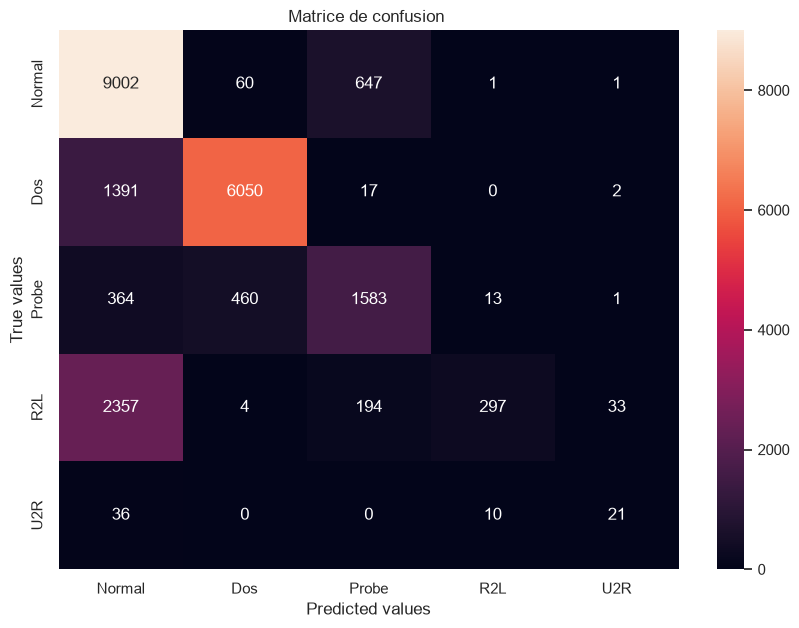

In [115]:
#METRIQUES 
# METRIQUES

for key,value in lrg_eval_results.items() :
    if key == "confusion_matrix":
        mat_conf(knn_evaluation["confusion_matrix"])
        break
    print(key ," : " ,  value)
    print("\n\n")